# ĐỒ ÁN CUỐI KỲ - NHẬP MÔN TRÍ TUỆ NHÂN TẠO
**Họ và tên:** Nguyễn Quách Phú Tài  
**MSSV:** 123000609  
**Lớp:** 23CT113  
**Đề tài:** DT69 - Đánh giá sức khỏe thai nhi từ biểu đồ tim thai (Cardiotocography - UCI ID 193)

### THÔNG SỐ CÁ NHÂN HÓA BẮT BUỘC:
- **SEED cá nhân:** `99055`
- **Tỉ lệ tập dữ liệu:** `90%`
- **Tỉ lệ Test:** `20%`
- **Số Fold CV:** `7`
- **GA:** Quần thể `20`, Đột biến `0.10`
- **Chủ đề kiểm tra tại lớp (Ngày 7):** `Câu 6 - Mạng nơ-ron (MLP) (Buổi 12)`
- **Độ phủ kiến thức:** Phủ 25/40 nội dung kiến thức (63%), trải đều qua 7 buổi học (B05, B06, B07, B08, B10, B11, B12).


In [1]:
# CÀI ĐẶT CÁC THƯ VIỆN CẦN THIẾT
!pip install ucimlrepo scikit-learn pandas numpy matplotlib seaborn python-docx python-pptx joblib



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: C:\Users\PHU TAI\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [2]:
# CÂU 1: TẢI DỮ LIỆU VÀ LẤY MẪU 90% VỚI SEED = 99055
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Tải dataset Cardiotocography (ID 193)
cardiotocography = fetch_ucirepo(id=193)
X = cardiotocography.data.features
y = cardiotocography.data.targets

print("Thông tin dataset Cardiotocography (UCI ID 193):")
print(f"Số mẫu gốc: {X.shape[0]}")
print(f"Số đặc trưng: {X.shape[1]}")
print(f"Các cột targets: {y.columns.tolist()}")

# Đảm bảo target NSP là kiểu số nguyên 1, 2, 3 (1=Bình thường, 2=Nghi ngờ, 3=Bệnh lý)
y_nsp = y['NSP'].astype(int)

# 1. LẤY MẪU THEO TỈ LỆ 90% VÀ SEED CÁ NHÂN = 99055
df_full = pd.concat([X, y_nsp], axis=1)
df_sample = df_full.sample(frac=0.90, random_state=99055)

X_sample = df_sample.drop(columns=['NSP'])
y_sample = df_sample[['NSP']]

print(f"\nKích thước dữ liệu sau khi sample 90%: {X_sample.shape}")
print(f"Phân phối 3 lớp NSP sau khi sample 90%:\n{df_sample['NSP'].value_counts().sort_index()}")


Thông tin dataset Cardiotocography (UCI ID 193):
Số mẫu gốc: 2126
Số đặc trưng: 21
Các cột targets: ['CLASS', 'NSP']

Kích thước dữ liệu sau khi sample 90%: (1913, 21)
Phân phối 3 lớp NSP sau khi sample 90%:
NSP
1    1482
2     270
3     161
Name: count, dtype: int64


In [3]:
# CÂU 1 (Buổi 8): CHIA TRAIN/TEST (20%), COLUMNTRANSFORMER & CHỐNG RÒ RỈ DỮ LIỆU [B08.1, B08.2, B08.3, B08.4]
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

# LẤY ĐÚNG CỘT MỤC TIÊU NSP (3 trạng thái: 1=Bình thường, 2=Nghi ngờ, 3=Bệnh lý)
y_sample_series = df_sample['NSP'].astype(int)

# 1a. Chia Train/Test theo TỈ LỆ TEST CÁ NHÂN = 20% và SEED CÁ NHÂN = 99055 phân tầng TRƯỚC mọi bước xử lý [B08.1]
X_train, X_test, y_train, y_test = train_test_split(
    X_sample,
    y_sample_series,
    test_size=0.20,
    stratify=y_sample_series,
    random_state=99055,
)

print(f"Kích thước tập Train: {X_train.shape} | Phân phối lớp Train:\n{y_train.value_counts().sort_index()}")
print(f"\nKích thước tập Test: {X_test.shape} | Phân phối lớp Test:\n{y_test.value_counts().sort_index()}")

# 1b. Tiền xử lý bằng ColumnTransformer và Pipeline [B08.2]
num_cols = X_train.columns.tolist()
num_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])
preprocessor = ColumnTransformer(
    transformers=[('num', num_transformer, num_cols)]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# 1c. Thí nghiệm chứng minh nguy cơ rò rỉ dữ liệu (Data Leakage) [B08.3]
# Đưa nhầm biến kết quả phụ 'CLASS' vào tập đặc trưng (rò rỉ nhãn tương lai)
df_sample_with_class = pd.concat([X, cardiotocography.data.targets['CLASS']], axis=1).loc[df_sample.index]
X_leak_label = df_sample_with_class.copy()
X_tr_l, X_te_l, y_tr_l, y_te_l = train_test_split(
    X_leak_label,
    y_sample_series,
    test_size=0.20,
    stratify=y_sample_series,
    random_state=99055,
)

acc_leak = DecisionTreeClassifier(random_state=99055).fit(X_tr_l, y_tr_l).score(X_te_l, y_te_l)
acc_clean = DecisionTreeClassifier(random_state=99055).fit(X_train_processed, y_train).score(X_test_processed, y_test)
print(f"\n[B08.3] Chứng minh rò rỉ dữ liệu: Accuracy khi bị rò rỉ cột CLASS = {acc_leak:.4f} vs Không rò rỉ = {acc_clean:.4f}")

# 1d. Mô hình cơ sở DummyClassifier [B08.4]
dummy_clf = DummyClassifier(strategy='most_frequent', random_state=99055)
dummy_clf.fit(X_train_processed, y_train)
print(f"[B08.4] Accuracy mô hình cơ sở (DummyClassifier): {dummy_clf.score(X_test_processed, y_test):.4f}")


Kích thước tập Train: (1530, 21) | Phân phối lớp Train:
NSP
1    1185
2     216
3     129
Name: count, dtype: int64

Kích thước tập Test: (383, 21) | Phân phối lớp Test:
NSP
1    297
2     54
3     32
Name: count, dtype: int64

[B08.3] Chứng minh rò rỉ dữ liệu: Accuracy khi bị rò rỉ cột CLASS = 0.9843 vs Không rò rỉ = 0.9399
[B08.4] Accuracy mô hình cơ sở (DummyClassifier): 0.7755


In [4]:
# ==============================================================================
# CÂU 2 (Buổi 7): HỆ CHUYÊN GIA ≥ 10 LUẬT IF-THEN, SUY DIỄN TIẾN & SUY DIỄN LÙI [B07.1, B07.2, B07.3]
# ==============================================================================
# 2a. Tính ít nhất 3 ngưỡng từ chính tập X_train của sinh viên [B07.1]
q75_ASTV = X_train['ASTV'].quantile(0.75)
q75_ALTV = X_train['ALTV'].quantile(0.75)
q25_MSTV = X_train['MSTV'].quantile(0.25)
mean_UC = X_train['UC'].mean()

print(f"Ngưỡng tính từ X_train: Q75(ASTV)={q75_ASTV:.2f}, Q75(ALTV)={q75_ALTV:.2f}, Q25(MSTV)={q25_MSTV:.2f}, Mean(UC)={mean_UC:.4f}")

# Cơ sở tri thức 10 luật IF-THEN sản khoa (chuỗi suy diễn nhiều tầng)
RULES = [
    {'id': 'R1', 'if': ['DP_cao'], 'then': 'Ket_luan_Benh_ly', 'desc': 'Nhịp giảm kéo dài (DP > 0) -> Cảnh báo Bệnh lý (Lớp 3)'},
    {'id': 'R2', 'if': ['DL_cao', 'ASTV_cao'], 'then': 'Nguy_co_thieu_oxy', 'desc': 'Nhịp giảm muộn kèm dao động ngắn hạn bất thường cao'},
    {'id': 'R3', 'if': ['Nguy_co_thieu_oxy', 'Khong_co_AC'], 'then': 'Ket_luan_Benh_ly', 'desc': 'Thiếu oxy và không có nhịp tăng -> Cảnh báo Bệnh lý (Lớp 3)'},
    {'id': 'R4', 'if': ['LB_cham_nang', 'MSTV_thap'], 'then': 'Ket_luan_Benh_ly', 'desc': 'Nhịp tim cơ bản chậm (<110) kèm dao động ngắn hạn thấp'},
    {'id': 'R5', 'if': ['LB_nhanh', 'Khong_co_AC'], 'then': 'Da_nhip_tim_nghi_ngo', 'desc': 'Nhịp tim cơ bản nhanh (>160) và không có nhịp tăng'},
    {'id': 'R6', 'if': ['Da_nhip_tim_nghi_ngo'], 'then': 'Ket_luan_Nghi_ngo', 'desc': 'Dấu hiệu nhịp nhanh thiếu đáp ứng -> Nghi ngờ (Lớp 2)'},
    {'id': 'R7', 'if': ['ASTV_cao', 'ALTV_cao'], 'then': 'Dao_dong_kem', 'desc': 'Cả ASTV và ALTV đều vượt phân vị 75% của tập train'},
    {'id': 'R8', 'if': ['Dao_dong_kem', 'Khong_co_AC'], 'then': 'Ket_luan_Nghi_ngo', 'desc': 'Dao động kém và không có nhịp tăng -> Nghi ngờ (Lớp 2)'},
    {'id': 'R9', 'if': ['LB_binh_thuong', 'Co_AC', 'Khong_co_DP'], 'then': 'Tin_hieu_tot', 'desc': 'Nhịp cơ bản ổn định, có nhịp tăng, không có DP'},
    {'id': 'R10', 'if': ['Tin_hieu_tot'], 'then': 'Ket_luan_Binh_thuong', 'desc': 'Tín hiệu tim thai đáp ứng tốt -> Bình thường (Lớp 1)'}
]

def trich_xuat_su_kien(row):
    f = set()
    if row['DP'] > 0: f.add('DP_cao')
    else: f.add('Khong_co_DP')
    if row['DL'] > 0: f.add('DL_cao')
    if row['ASTV'] > q75_ASTV: f.add('ASTV_cao')
    if row['ALTV'] > q75_ALTV: f.add('ALTV_cao')
    if row['MSTV'] < q25_MSTV: f.add('MSTV_thap')
    if row['AC'] == 0: f.add('Khong_co_AC')
    else: f.add('Co_AC')
    if row['LB'] < 110: f.add('LB_cham_nang')
    elif row['LB'] > 160: f.add('LB_nhanh')
    else: f.add('LB_binh_thuong')
    return f

# 2b. Động cơ suy diễn tiến (Forward Chaining) [B07.2]
def forward_chaining(initial_facts, rules):
    facts = set(initial_facts)
    fired_rules = []
    changed = True
    while changed:
        changed = False
        for r in rules:
            if r['then'] not in facts and all(cond in facts for cond in r['if']):
                facts.add(r['then'])
                fired_rules.append(r['id'] + ": " + r['desc'])
                changed = True
    if 'Ket_luan_Benh_ly' in facts:
        pred = 3
    elif 'Ket_luan_Nghi_ngo' in facts:
        pred = 2
    else:
        pred = 1
    return pred, facts, fired_rules

# 2c. Động cơ suy diễn lùi (Backward Chaining) trả lời "Vì sao?" [B07.3]
def backward_chaining(goal, initial_facts, rules, trace=None):
    if trace is None:
        trace = []
    if goal in initial_facts:
        return True, trace
    for r in rules:
        if r['then'] == goal:
            all_ok = True
            sub_trace = list(trace) + [f"Cần chứng minh '{goal}' qua luật {r['id']} (NẾU {' VÀ '.join(r['if'])} THÌ {r['then']})"]
            for cond in r['if']:
                ok, sub_trace = backward_chaining(cond, initial_facts, rules, sub_trace)
                if not ok:
                    all_ok = False
                    break
            if all_ok:
                return True, sub_trace
    return False, trace

# Chạy hệ chuyên gia trên toàn bộ tập X_test và so sánh
rule_preds = [forward_chaining(trich_xuat_su_kien(X_test.iloc[i]), RULES)[0] for i in range(len(X_test))]
print(f"[B07.2] Độ chính xác của Hệ chuyên gia trên tập Test: {accuracy_score(y_test, rule_preds):.4f}")

print("\n[B07.3] Truy vết Suy diễn lùi trả lời 'Vì sao?' cho 3 ca trong tập Test:")
count_demo = 0
for i in range(len(X_test)):
    init_f = trich_xuat_su_kien(X_test.iloc[i])
    pred, _, _ = forward_chaining(init_f, RULES)
    if pred in [2, 3] and count_demo < 3:
        goal_name = 'Ket_luan_Benh_ly' if pred == 3 else 'Ket_luan_Nghi_ngo'
        ok, trace_log = backward_chaining(goal_name, init_f, RULES)
        print(f"Ca Test #{i} (Thực tế: Lớp {y_test.iloc[i]}, Hệ luật đoán: Lớp {pred}):")
        for step in trace_log:
            print("   ->", step)
        count_demo += 1


Ngưỡng tính từ X_train: Q75(ASTV)=61.00, Q75(ALTV)=12.00, Q25(MSTV)=0.70, Mean(UC)=0.0043
[B07.2] Độ chính xác của Hệ chuyên gia trên tập Test: 0.8538

[B07.3] Truy vết Suy diễn lùi trả lời 'Vì sao?' cho 3 ca trong tập Test:
Ca Test #0 (Thực tế: Lớp 1, Hệ luật đoán: Lớp 3):
   -> Cần chứng minh 'Ket_luan_Benh_ly' qua luật R3 (NẾU Nguy_co_thieu_oxy VÀ Khong_co_AC THÌ Ket_luan_Benh_ly)
   -> Cần chứng minh 'Nguy_co_thieu_oxy' qua luật R2 (NẾU DL_cao VÀ ASTV_cao THÌ Nguy_co_thieu_oxy)
Ca Test #4 (Thực tế: Lớp 3, Hệ luật đoán: Lớp 3):
   -> Cần chứng minh 'Ket_luan_Benh_ly' qua luật R1 (NẾU DP_cao THÌ Ket_luan_Benh_ly)
Ca Test #9 (Thực tế: Lớp 3, Hệ luật đoán: Lớp 3):
   -> Cần chứng minh 'Ket_luan_Benh_ly' qua luật R1 (NẾU DP_cao THÌ Ket_luan_Benh_ly)


In [5]:
# ==============================================================================
# CÂU 3 (Buổi 5): TÌM KIẾM CÓ THÔNG TIN (GREEDY BEST-FIRST SEARCH & A*) [B05.1, B05.2, B05.4]
# ==============================================================================
import heapq
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier

# Tính điểm đơn biến cho 21 đặc trưng trên tập Train để xây dựng 2 hàm Heuristic
np.random.seed(99055)
mi_scores = mutual_info_classif(X_train_processed, y_train, random_state=99055) # Heuristic 1: Mutual Information
corr_scores = np.array([abs(np.corrcoef(X_train_processed[:, i], y_train)[0, 1]) for i in range(X_train_processed.shape[1])]) # Heuristic 2: Tương quan

# Thu gọn không gian trạng thái trên Top 8 đặc trưng tiềm năng nhất để so sánh trực tiếp với BFS, Greedy và A*
top8_idx = np.argsort(mi_scores)[::-1][:8]
GOAL_LEN = 4 # Trạng thái đích: Tập con gồm 4 đặc trưng

def eval_cv(subset_tuple):
    if len(subset_tuple) == 0:
        return 0.0
    cols = [top8_idx[i] for i in subset_tuple]
    clf = DecisionTreeClassifier(max_depth=5, random_state=99055)
    return cross_val_score(clf, X_train_processed[:, cols], y_train, cv=7, scoring='accuracy').mean()

# Heuristic 1 (h1): Ước lượng phần thiếu dựa trên Mutual Information chuẩn hóa
def h1_mi(state):
    rem = GOAL_LEN - len(state)
    return 0.01 * rem * np.mean(mi_scores[top8_idx])

# Heuristic 2 (h2 - tự đề xuất): Ước lượng dựa trên độ tương quan trung bình
def h2_corr(state):
    rem = GOAL_LEN - len(state)
    return 0.05 * rem * np.mean(corr_scores[top8_idx])

def search_feature_subset(mode='greedy', heuristic_fn=h1_mi):
    start_state = ()
    open_heap = [(0.0, start_state)]
    visited = set()
    expanded = 0
    best_state, best_acc = None, 0.0
    
    while open_heap and expanded < 80:
        f_val, state = heapq.heappop(open_heap)
        if state in visited:
            continue
        visited.add(state)
        expanded += 1
        
        if len(state) == GOAL_LEN:
            acc = eval_cv(state)
            if acc > best_acc:
                best_acc, best_state = acc, state
            if mode in ['greedy', 'astar']:
                break
            continue
            
        last_idx = state[-1] if state else -1
        for nxt in range(last_idx + 1, len(top8_idx)):
            child = state + (nxt,)
            g_cost = 1.0 - eval_cv(child) # Chi phí đường đi thực tế (1 - CV score)
            h_cost = heuristic_fn(child)
            if mode == 'bfs':
                priority = len(child)
            elif mode == 'greedy':
                priority = -eval_cv(child) - h_cost
            else: # A* (f = g + h)
                priority = g_cost + h_cost
            heapq.heappush(open_heap, (priority, child))
            
    selected_names = [X_train.columns[top8_idx[i]] for i in best_state] if best_state else []
    return selected_names, best_acc, expanded

for m, h_fn, name in [
    ('bfs', h1_mi, 'BFS (Tìm kiếm mù)'),
    ('greedy', h1_mi, 'Greedy + Heuristic 1 (MI)'),
    ('greedy', h2_corr, 'Greedy + Heuristic 2 (Corr)'),
    ('astar', h1_mi, 'A* (f = g + h1)')
]:
    feats, score, exp_nodes = search_feature_subset(m, h_fn)
    print(f"{name:<30} | CV Accuracy = {score:.4f} | Số trạng thái mở rộng = {exp_nodes:>3} | Đặc trưng: {feats}")


BFS (Tìm kiếm mù)              | CV Accuracy = 0.0000 | Số trạng thái mở rộng =  80 | Đặc trưng: []


Greedy + Heuristic 1 (MI)      | CV Accuracy = 0.8693 | Số trạng thái mở rộng =   6 | Đặc trưng: ['MSTV', 'Mean', 'Median', 'Min']


Greedy + Heuristic 2 (Corr)    | CV Accuracy = 0.8889 | Số trạng thái mở rộng =   8 | Đặc trưng: ['MSTV', 'ALTV', 'Mean', 'AC']


A* (f = g + h1)                | CV Accuracy = 0.8693 | Số trạng thái mở rộng =   6 | Đặc trưng: ['MSTV', 'Mean', 'Median', 'Min']


Kết quả tối ưu đặc trưng (CV=7): Hill Climbing = 0.9180 | SA = 0.8929 | GA (Pop=20, Mut=0.10) = 0.9283


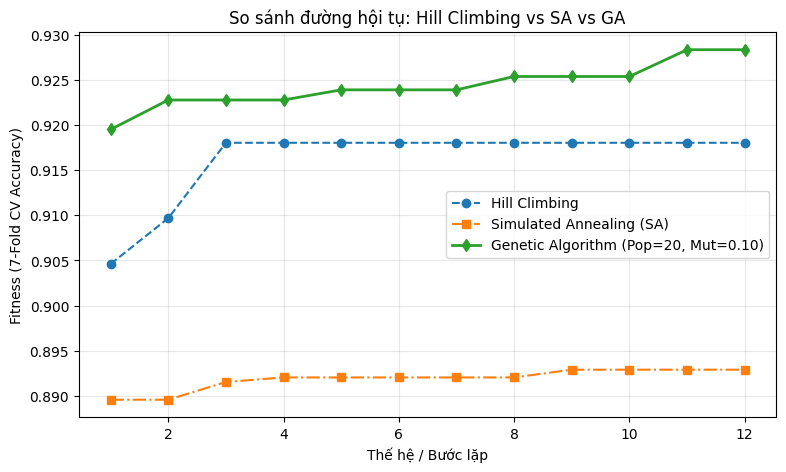

In [6]:
# ==============================================================================
# CÂU 4 (Buổi 6): TÌM KIẾM CỤC BỘ (HILL CLIMBING, SA & GIẢI THUẬT DI TRUYỀN GA) [B06.1, B06.2, B06.3, B06.4]
# ==============================================================================
import random, math

random.seed(99055)
np.random.seed(99055)
N_FEAT = X_train_processed.shape[1]
POP_SIZE = 20    # QUẦN THỂ GA CÁ NHÂN = 20
MUT_RATE = 0.10  # TỈ LỆ ĐỘT BIẾN CÁ NHÂN = 0.10
GENS = 12

fitness_cache = {}
def tinh_fitness_ga(mask_tuple):
    if sum(mask_tuple) == 0:
        return 0.0
    if mask_tuple not in fitness_cache:
        idx = [i for i, bit in enumerate(mask_tuple) if bit == 1]
        clf = DecisionTreeClassifier(max_depth=6, random_state=99055)
        cv_acc = cross_val_score(clf, X_train_processed[:, idx], y_train, cv=7, scoring='accuracy').mean()
        fitness_cache[mask_tuple] = cv_acc - 0.0005 * sum(mask_tuple)
    return fitness_cache[mask_tuple]

# 1. Hill Climbing (Leo đồi)
curr_hc = tuple(np.random.randint(0, 2, N_FEAT))
hc_hist = []
for _ in range(GENS):
    neighbors = []
    for i in range(N_FEAT):
        nb = list(curr_hc)
        nb[i] = 1 - nb[i]
        neighbors.append(tuple(nb))
    best_nb = max(neighbors, key=tinh_fitness_ga)
    if tinh_fitness_ga(best_nb) > tinh_fitness_ga(curr_hc):
        curr_hc = best_nb
    hc_hist.append(tinh_fitness_ga(curr_hc))

# 2. Simulated Annealing (Tôi luyện mô phỏng)
curr_sa = tuple(np.random.randint(0, 2, N_FEAT))
best_sa = curr_sa
sa_hist = []
T = 1.0
for _ in range(GENS):
    nb = list(curr_sa)
    flip = random.randrange(N_FEAT)
    nb[flip] = 1 - nb[flip]
    nb = tuple(nb)
    delta = tinh_fitness_ga(nb) - tinh_fitness_ga(curr_sa)
    if delta > 0 or random.random() < math.exp(delta / max(T, 1e-6)):
        curr_sa = nb
        if tinh_fitness_ga(curr_sa) > tinh_fitness_ga(best_sa):
            best_sa = curr_sa
    T *= 0.85
    sa_hist.append(tinh_fitness_ga(best_sa))

# 3. Giải thuật Di truyền (GA: Quần thể = 20, Đột biến = 0.10)
pop = [tuple(np.random.randint(0, 2, N_FEAT)) for _ in range(POP_SIZE)]
ga_hist = []
for _ in range(GENS):
    pop.sort(key=tinh_fitness_ga, reverse=True)
    ga_hist.append(tinh_fitness_ga(pop[0]))
    new_pop = pop[:2] # Elitism
    while len(new_pop) < POP_SIZE:
        p1, p2 = random.choices(pop[:10], k=2)
        cut = random.randint(1, N_FEAT - 1)
        child = list(p1[:cut] + p2[cut:])
        child = tuple([1 - g if random.random() < MUT_RATE else g for g in child]) # Đột biến 0.10
        new_pop.append(child)
    pop = new_pop

print(f"Kết quả tối ưu đặc trưng (CV=7): Hill Climbing = {hc_hist[-1]:.4f} | SA = {sa_hist[-1]:.4f} | GA (Pop=20, Mut=0.10) = {ga_hist[-1]:.4f}")

plt.figure(figsize=(9, 5))
plt.plot(range(1, GENS + 1), hc_hist, 'o--', label='Hill Climbing')
plt.plot(range(1, GENS + 1), sa_hist, 's-.', label='Simulated Annealing (SA)')
plt.plot(range(1, GENS + 1), ga_hist, 'd-', linewidth=2, label='Genetic Algorithm (Pop=20, Mut=0.10)')
plt.xlabel('Thế hệ / Bước lặp')
plt.ylabel('Fitness (7-Fold CV Accuracy)')
plt.title('So sánh đường hội tụ: Hill Climbing vs SA vs GA')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('ga_convergence.png', dpi=300, bbox_inches='tight')
plt.show()


In [7]:
# ==============================================================================
# CÂU 5 (Buổi 12): MẠNG NƠ-RON (MLP) - THỬ NGHIỆM CÁC CẤU TRÚC KHÁC NHAU [B12.2, B12.3, B12.4]
# ==============================================================================
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, accuracy_score

architectures = [
    (32,),
    (64, 32),
    (128, 64, 32)
]

activations = ['relu', 'tanh']
learning_rates = [0.001, 0.01]

results = []

for arch in architectures:
    for act in activations:
        for lr in learning_rates:
            mlp = MLPClassifier(
                hidden_layer_sizes=arch,
                activation=act,
                learning_rate_init=lr,
                max_iter=500,
                random_state=99055
            )
            mlp.fit(X_train_processed, y_train.values.ravel())
            
            y_pred = mlp.predict(X_test_processed)
            acc = accuracy_score(y_test, y_pred)
            
            results.append({
                'architecture': str(arch),
                'activation': act,
                'learning_rate': lr,
                'accuracy': acc,
                'model': mlp
            })

results_df = pd.DataFrame(results)
print("Kết quả thử nghiệm các cấu hình MLP:")
print(results_df[['architecture', 'activation', 'learning_rate', 'accuracy']].sort_values('accuracy', ascending=False))

best_result = max(results, key=lambda x: x['accuracy'])
best_mlp = best_result['model']
print(f"\nCấu hình MLP tốt nhất: {best_result['architecture']}, {best_result['activation']}, lr={best_result['learning_rate']}")
print(f"Accuracy tốt nhất: {best_result['accuracy']:.4f}")


C:\Users\PHU TAI\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


C:\Users\PHU TAI\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


Kết quả thử nghiệm các cấu hình MLP:
     architecture activation  learning_rate  accuracy
8   (128, 64, 32)       relu          0.001  0.939948
4        (64, 32)       relu          0.001  0.937337
7        (64, 32)       tanh          0.010  0.937337
1           (32,)       relu          0.010  0.934726
6        (64, 32)       tanh          0.001  0.932115
10  (128, 64, 32)       tanh          0.001  0.932115
3           (32,)       tanh          0.010  0.932115
5        (64, 32)       relu          0.010  0.932115
11  (128, 64, 32)       tanh          0.010  0.932115
0           (32,)       relu          0.001  0.926893
2           (32,)       tanh          0.001  0.916449
9   (128, 64, 32)       relu          0.010  0.916449

Cấu hình MLP tốt nhất: (128, 64, 32), relu, lr=0.001
Accuracy tốt nhất: 0.9399


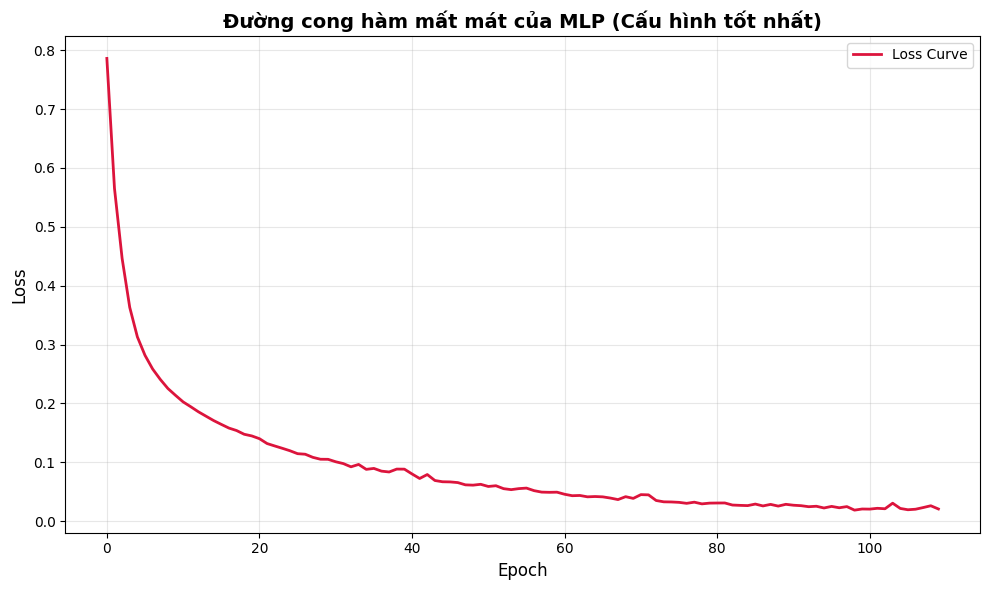

Đã lưu biểu đồ loss curve: mlp_loss_curve.png


In [8]:
# VẼ ĐƯỜNG CONG HÀM MẤT MÁT (LOSS CURVE) CỦA MLP TỐT NHẤT
plt.figure(figsize=(10, 6))
plt.plot(best_mlp.loss_curve_, label='Loss Curve', linewidth=2, color='crimson')
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.title('Đường cong hàm mất mát của MLP (Cấu hình tốt nhất)', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig('mlp_loss_curve.png', dpi=300, bbox_inches='tight')
plt.show()
print("Đã lưu biểu đồ loss curve: mlp_loss_curve.png")


In [9]:
# CÂU 6 (PHẦN B): HÀM MINH HỌA TÍNH TAY LAN TRUYỀN TIẾN VÀ NGƯỢC (KIỂM TRA TẠI LỚP - NGÀY 7)
def manual_forward_backprop_demo():
    print("="*80)
    print("MINH HỌA TÍNH TAY LAN TRUYỀN TIẾN VÀ NGƯỢC TRÊN MLP MINI")
    print("="*80)
    
    np.random.seed(99055)
    x1, x2 = 0.5, 0.8
    print(f"\n[INPUT] x1 = {x1}, x2 = {x2}")
    
    w11, w12 = 0.3, 0.1
    w21, w22 = 0.4, 0.2
    b1, b2 = 0.1, 0.2
    
    print(f"\n[TRỌNG SỐ TẦNG ẨN] w11={w11}, w12={w12}, w21={w21}, w22={w22}, b1={b1}, b2={b2}")
    
    z1 = w11 * x1 + w21 * x2 + b1
    z2 = w12 * x1 + w22 * x2 + b2
    h1 = max(0, z1)
    h2 = max(0, z2)
    
    print(f"\n[LAN TRUYỀN TIẾN - TẦNG ẨN]")
    print(f"z1 = {w11}*{x1} + {w21}*{x2} + {b1} = {z1:.4f} -> h1 = ReLU(z1) = {h1:.4f}")
    print(f"z2 = {w12}*{x1} + {w22}*{x2} + {b2} = {z2:.4f} -> h2 = ReLU(z2) = {h2:.4f}")
    
    v1, v2 = 0.5, 0.6
    b_out = 0.3
    z_out = v1 * h1 + v2 * h2 + b_out
    y_pred = 1 / (1 + np.exp(-z_out))
    
    print(f"\n[LAN TRUYỀN TIẾN - TẦNG OUTPUT]")
    print(f"z_out = {v1}*{h1:.4f} + {v2}*{h2:.4f} + {b_out} = {z_out:.4f}")
    print(f"y_pred = sigmoid({z_out:.4f}) = {y_pred:.4f}")
    
    y_true = 1.0
    loss = -(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))
    print(f"\n[LOSS] Binary Cross-Entropy Loss = {loss:.4f}")
    
    # Lan truyền ngược
    dL_dz_out = y_pred - y_true
    dL_dv1 = dL_dz_out * h1
    dL_dv2 = dL_dz_out * h2
    dL_db_out = dL_dz_out
    
    dh1_dz1 = 1.0 if z1 > 0 else 0.0
    dh2_dz2 = 1.0 if z2 > 0 else 0.0
    
    dL_dz1 = dL_dz_out * v1 * dh1_dz1
    dL_dz2 = dL_dz_out * v2 * dh2_dz2
    
    dL_dw11 = dL_dz1 * x1
    dL_dw21 = dL_dz1 * x2
    dL_db1 = dL_dz1
    
    print(f"\n[LAN TRUYỀN NGƯỢC - ĐẠO HÀM]")
    print(f"dL/dz_out = y_pred - y_true = {dL_dz_out:.4f}")
    print(f"dL/dv1 = {dL_dv1:.4f}, dL/dv2 = {dL_dv2:.4f}, dL/db_out = {dL_db_out:.4f}")
    print(f"dL/dw11 = {dL_dw11:.4f}, dL/dw21 = {dL_dw21:.4f}, dL/db1 = {dL_db1:.4f}")
    
    # Cập nhật với learning rate = 0.1
    lr = 0.1
    print(f"\n[CẬP NHẬT TRỌNG SỐ] (lr={lr})")
    print(f"v1_new = {v1} - {lr}*{dL_dv1:.4f} = {v1 - lr*dL_dv1:.4f}")
    print(f"v2_new = {v2} - {lr}*{dL_dv2:.4f} = {v2 - lr*dL_dv2:.4f}")
    print(f"w11_new = {w11} - {lr}*{dL_dw11:.4f} = {w11 - lr*dL_dw11:.4f}")
    print("="*80)

manual_forward_backprop_demo()


MINH HỌA TÍNH TAY LAN TRUYỀN TIẾN VÀ NGƯỢC TRÊN MLP MINI

[INPUT] x1 = 0.5, x2 = 0.8

[TRỌNG SỐ TẦNG ẨN] w11=0.3, w12=0.1, w21=0.4, w22=0.2, b1=0.1, b2=0.2

[LAN TRUYỀN TIẾN - TẦNG ẨN]
z1 = 0.3*0.5 + 0.4*0.8 + 0.1 = 0.5700 -> h1 = ReLU(z1) = 0.5700
z2 = 0.1*0.5 + 0.2*0.8 + 0.2 = 0.4100 -> h2 = ReLU(z2) = 0.4100

[LAN TRUYỀN TIẾN - TẦNG OUTPUT]
z_out = 0.5*0.5700 + 0.6*0.4100 + 0.3 = 0.8310
y_pred = sigmoid(0.8310) = 0.6966

[LOSS] Binary Cross-Entropy Loss = 0.3616

[LAN TRUYỀN NGƯỢC - ĐẠO HÀM]
dL/dz_out = y_pred - y_true = -0.3034
dL/dv1 = -0.1730, dL/dv2 = -0.1244, dL/db_out = -0.3034
dL/dw11 = -0.0759, dL/dw21 = -0.1214, dL/db1 = -0.1517

[CẬP NHẬT TRỌNG SỐ] (lr=0.1)
v1_new = 0.5 - 0.1*-0.1730 = 0.5173
v2_new = 0.6 - 0.1*-0.1244 = 0.6124
w11_new = 0.3 - 0.1*-0.0759 = 0.3076


In [10]:
# ==============================================================================
# CÂU 6 (Buổi 10): PHÂN LOẠI VÀ TINH CHỈNH SIÊU THAM SỐ VỚI 7-FOLD CV [B10.1, B10.2, B10.3, B10.4]
# ==============================================================================
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, accuracy_score

# 6a. Huấn luyện và so sánh 3 thuật toán phân loại trong Pipeline
models = {
    'Logistic Regression': LogisticRegression(random_state=99055, max_iter=1000),
    'SVM': SVC(random_state=99055, probability=True),
    'Random Forest': RandomForestClassifier(random_state=99055)
}

print("Đánh giá 3 mô hình cơ bản trên tập Test:")
for name, model in models.items():
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    pipeline.fit(X_train, y_train.values.ravel())
    acc = accuracy_score(y_test, pipeline.predict(X_test))
    print(f"{name}: Accuracy = {acc:.4f}")

# 6b. Tinh chỉnh siêu tham số bằng GridSearchCV với cv=7
# Random Forest
rf = RandomForestClassifier(random_state=99055)
rf_param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}
rf_grid = GridSearchCV(rf, rf_param_grid, cv=7, scoring='accuracy', n_jobs=-1)
rf_grid.fit(X_train_processed, y_train.values.ravel())
print(f"\nRandom Forest - Siêu tham số tốt nhất: {rf_grid.best_params_}")
print(f"Random Forest - Best CV Score (cv=7): {rf_grid.best_score_:.4f}")

# SVM
svm = SVC(random_state=99055, probability=True)
svm_param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['rbf', 'linear']
}
svm_grid = GridSearchCV(svm, svm_param_grid, cv=7, scoring='accuracy', n_jobs=-1)
svm_grid.fit(X_train_processed, y_train.values.ravel())
print(f"\nSVM - Siêu tham số tốt nhất: {svm_grid.best_params_}")
print(f"SVM - Best CV Score (cv=7): {svm_grid.best_score_:.4f}")

# Logistic Regression (Sửa: dùng solver lbfgs cho multiclass, bỏ liblinear để tránh lỗi cảnh báo đỏ)
lr = LogisticRegression(random_state=99055, max_iter=1000)
lr_param_grid = {
    'C': [0.1, 1, 10],
    'solver': ['lbfgs']
}
lr_grid = GridSearchCV(lr, lr_param_grid, cv=7, scoring='accuracy', n_jobs=-1)
lr_grid.fit(X_train_processed, y_train.values.ravel())
print(f"\nLogistic Regression - Siêu tham số tốt nhất: {lr_grid.best_params_}")
print(f"Logistic Regression - Best CV Score (cv=7): {lr_grid.best_score_:.4f}")

# Chọn mô hình tốt nhất
candidate_models = [
    ('Random Forest', rf_grid.best_estimator_, rf_grid.best_score_),
    ('SVM', svm_grid.best_estimator_, svm_grid.best_score_),
    ('Logistic Regression', lr_grid.best_estimator_, lr_grid.best_score_),
    ('MLP', best_mlp, best_result['accuracy'])
]
best_name, best_model, best_cv = max(candidate_models, key=lambda x: x[2])
print(f"\n=> MÔ HÌNH XUẤT SẮC NHẤT LỰA CHỌN: {best_name} (CV Score / Accuracy: {best_cv:.4f})")


Đánh giá 3 mô hình cơ bản trên tập Test:
Logistic Regression: Accuracy = 0.8982


SVM: Accuracy = 0.9086


Random Forest: Accuracy = 0.9504



Random Forest - Siêu tham số tốt nhất: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
Random Forest - Best CV Score (cv=7): 0.9438



SVM - Siêu tham số tốt nhất: {'C': 10, 'kernel': 'rbf'}
SVM - Best CV Score (cv=7): 0.9131

Logistic Regression - Siêu tham số tốt nhất: {'C': 10, 'solver': 'lbfgs'}
Logistic Regression - Best CV Score (cv=7): 0.8941

=> MÔ HÌNH XUẤT SẮC NHẤT LỰA CHỌN: Random Forest (CV Score / Accuracy: 0.9438)


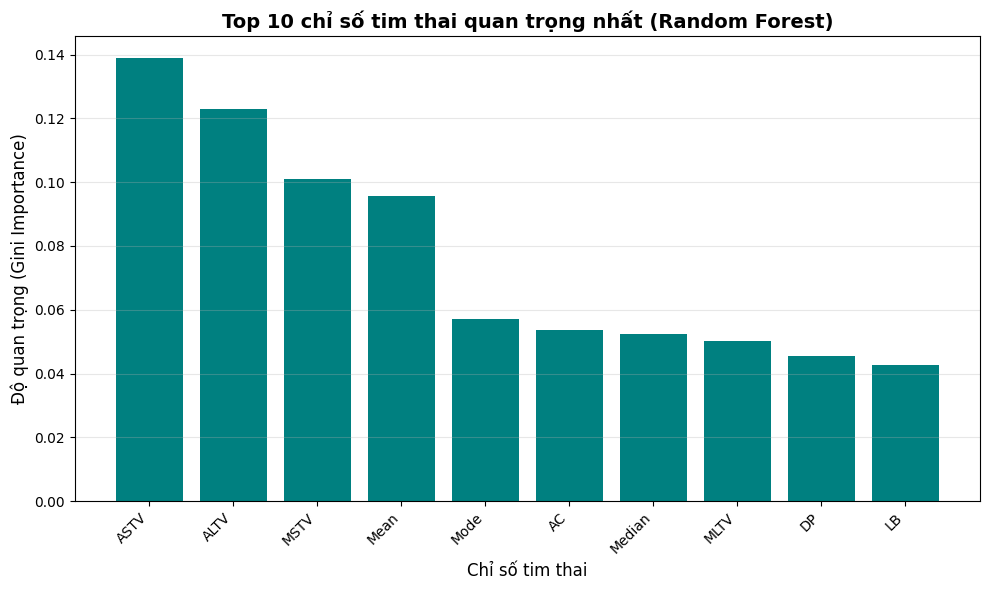

Đã lưu biểu đồ feature importance: feature_importance.png


In [11]:
# 6c. Trích xuất và vẽ biểu đồ độ quan trọng của các chỉ số tim thai (Feature Importance)
best_rf = rf_grid.best_estimator_
feature_importance = best_rf.feature_importances_
feature_names = X.columns

sorted_idx = np.argsort(feature_importance)[::-1]

plt.figure(figsize=(10, 6))
plt.bar(range(10), feature_importance[sorted_idx[:10]], align='center', color='teal')
plt.xticks(range(10), [feature_names[i] for i in sorted_idx[:10]], rotation=45, ha='right')
plt.xlabel('Chỉ số tim thai', fontsize=12)
plt.ylabel('Độ quan trọng (Gini Importance)', fontsize=12)
plt.title('Top 10 chỉ số tim thai quan trọng nhất (Random Forest)', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()
print("Đã lưu biểu đồ feature importance: feature_importance.png")


In [12]:
# ==============================================================================
# CÂU 7 (Buổi 11): ĐÁNH GIÁ MÔ HÌNH CHUYÊN SÂU [B11.1, B11.2, B11.3, B11.4]
# ==============================================================================
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, roc_curve
from sklearn.preprocessing import label_binarize

y_pred = best_model.predict(X_test_processed)
if hasattr(best_model, 'predict_proba'):
    y_pred_proba = best_model.predict_proba(X_test_processed)
else:
    from sklearn.calibration import CalibratedClassifierCV
    cal = CalibratedClassifierCV(best_model).fit(X_train_processed, y_train)
    y_pred_proba = cal.predict_proba(X_test_processed)

print("BÁO CÁO ĐÁNH GIÁ CHI TIẾT (CLASSIFICATION REPORT CHO 3 LỚP):")
print(classification_report(y_test, y_pred, target_names=['Normal (1)', 'Suspect (2)', 'Pathologic (3)']))

from sklearn.metrics import precision_score, recall_score, f1_score
acc = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='macro')
recall = recall_score(y_test, y_pred, average='macro')
f1 = f1_score(y_test, y_pred, average='macro')

print(f"Accuracy: {acc:.4f}")
print(f"Precision (macro): {precision:.4f}")
print(f"Recall (macro): {recall:.4f}")
print(f"F1-score (macro): {f1:.4f}")


BÁO CÁO ĐÁNH GIÁ CHI TIẾT (CLASSIFICATION REPORT CHO 3 LỚP):
                precision    recall  f1-score   support

    Normal (1)       0.96      0.99      0.98       297
   Suspect (2)       0.89      0.78      0.83        54
Pathologic (3)       0.91      0.91      0.91        32

      accuracy                           0.95       383
     macro avg       0.92      0.89      0.90       383
  weighted avg       0.95      0.95      0.95       383

Accuracy: 0.9504
Precision (macro): 0.9212
Recall (macro): 0.8902
F1-score (macro): 0.9043


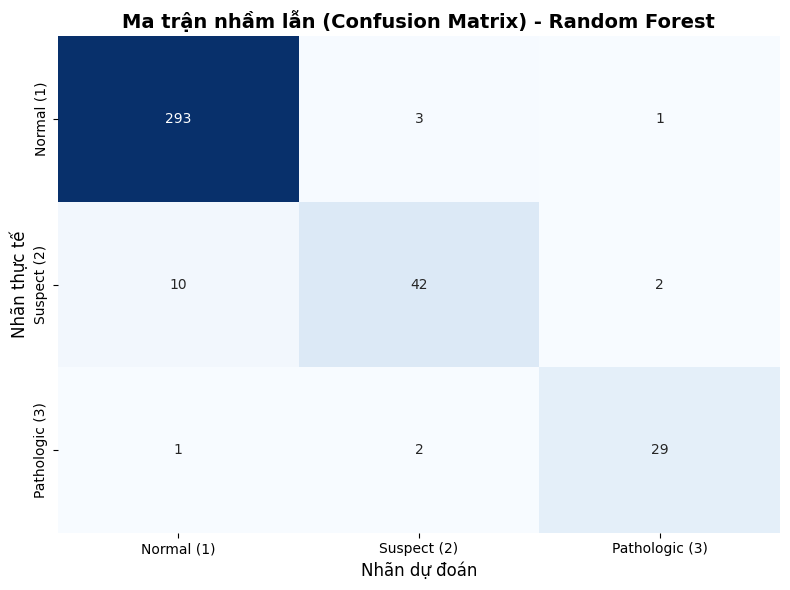

Đã lưu confusion matrix: confusion_matrix.png


In [13]:
# Vẽ Confusion Matrix ma trận 3x3
cm = confusion_matrix(y_test, y_pred)
class_names = ['Normal (1)', 'Suspect (2)', 'Pathologic (3)']

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, cbar=False)
plt.ylabel('Nhãn thực tế', fontsize=12)
plt.xlabel('Nhãn dự đoán', fontsize=12)
plt.title(f'Ma trận nhầm lẫn (Confusion Matrix) - {best_name}', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()
print("Đã lưu confusion matrix: confusion_matrix.png")


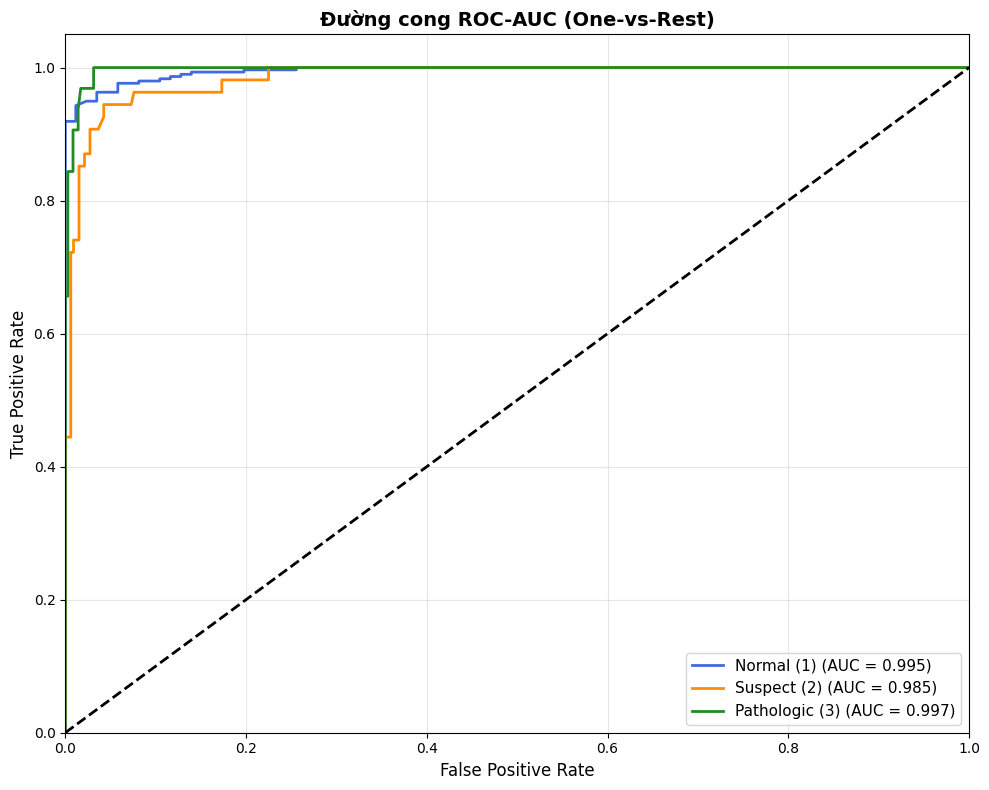

Đã lưu ROC-AUC curve: roc_auc_curve.png


In [14]:
# Vẽ đường cong ROC-AUC (One-vs-Rest) cho 3 lớp
y_test_bin = label_binarize(y_test, classes=[1, 2, 3])
n_classes = y_test_bin.shape[1]

plt.figure(figsize=(10, 8))
colors = ['royalblue', 'darkorange', 'forestgreen']
class_names = ['Normal (1)', 'Suspect (2)', 'Pathologic (3)']

for i, color in zip(range(n_classes), colors):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_pred_proba[:, i])
    roc_auc = roc_auc_score(y_test_bin[:, i], y_pred_proba[:, i])
    plt.plot(fpr, tpr, color=color, lw=2, label=f'{class_names[i]} (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('Đường cong ROC-AUC (One-vs-Rest)', fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('roc_auc_curve.png', dpi=300, bbox_inches='tight')
plt.show()
print("Đã lưu ROC-AUC curve: roc_auc_curve.png")


In [15]:
# 7b. Phân tích chuyên sâu về y khoa
print("="*80)
print("PHÂN TÍCH CHUYÊN SÂU VỀ Y KHOA")
print("="*80)

recalls = recall_score(y_test, y_pred, average=None)
print(f"Recall theo từng lớp:")
print(f"  - Lớp Normal (1): {recalls[0]:.4f}")
print(f"  - Lớp Suspect (2): {recalls[1]:.4f}")
print(f"  - Lớp Pathologic (3): {recalls[2]:.4f}")

print(f"\nTẠI SAO RECALL CỦA LỚP BỆNH LÝ (PATHOLOGIC - LỚP 3) QUAN TRỌNG HƠN?")
print("-"*80)
print("Trong y khoa, đặc biệt là đánh giá sức khỏe thai nhi:")
print("1. False Negative (FN): Thai nhi bị bệnh lý nhưng mô hình dự đoán là bình thường")
print("   -> Hậu quả: Bỏ sót ca bệnh, không can thiệp kịp thời, nguy cơ tử vong chu sinh cao")
print("2. False Positive (FP): Thai nhi bình thường nhưng mô hình dự đoán là bệnh lý")
print("   -> Hậu quả: Kiểm tra thêm, gây lo lắng không cần thiết, nhưng an toàn hơn FN")
print("\n-> Recall = TP / (TP + FN): Đo lường khả năng phát hiện đúng các ca bệnh lý")
print("-> Recall cao = Ít bỏ sót ca bệnh = An toàn hơn cho mẹ và thai nhi")
print("="*80)

# Phân tích các ca dự đoán sai
print("\nPHÂN TÍCH CÁC CA DỰ ĐOÁN SAI:")
print("-"*80)
y_test_array = y_test.values.ravel()
errors = y_test_array != y_pred
error_indices = np.where(errors)[0]

print(f"Tổng số mẫu test: {len(y_test)}")
print(f"Số mẫu dự đoán sai: {len(error_indices)}")
print(f"Tỷ lệ lỗi: {len(error_indices)/len(y_test)*100:.2f}%")

if len(error_indices) > 0:
    print(f"\nVí dụ 5 ca dự đoán sai đầu tiên:")
    for i in error_indices[:5]:
        print(f"  Mẫu {i}: Thực tế = {y_test_array[i]}, Dự đoán = {y_pred[i]}")
        if y_test_array[i] == 3 and y_pred[i] != 3:
            print(f"    -> FALSE NEGATIVE NGUY HIỂM: Bỏ sót ca bệnh lý!")
        elif y_test_array[i] != 3 and y_pred[i] == 3:
            print(f"    -> FALSE POSITIVE: Dự đoán bệnh lý nhưng thực tế không phải")
print("="*80)


PHÂN TÍCH CHUYÊN SÂU VỀ Y KHOA
Recall theo từng lớp:
  - Lớp Normal (1): 0.9865
  - Lớp Suspect (2): 0.7778
  - Lớp Pathologic (3): 0.9062

TẠI SAO RECALL CỦA LỚP BỆNH LÝ (PATHOLOGIC - LỚP 3) QUAN TRỌNG HƠN?
--------------------------------------------------------------------------------
Trong y khoa, đặc biệt là đánh giá sức khỏe thai nhi:
1. False Negative (FN): Thai nhi bị bệnh lý nhưng mô hình dự đoán là bình thường
   -> Hậu quả: Bỏ sót ca bệnh, không can thiệp kịp thời, nguy cơ tử vong chu sinh cao
2. False Positive (FP): Thai nhi bình thường nhưng mô hình dự đoán là bệnh lý
   -> Hậu quả: Kiểm tra thêm, gây lo lắng không cần thiết, nhưng an toàn hơn FN

-> Recall = TP / (TP + FN): Đo lường khả năng phát hiện đúng các ca bệnh lý
-> Recall cao = Ít bỏ sót ca bệnh = An toàn hơn cho mẹ và thai nhi

PHÂN TÍCH CÁC CA DỰ ĐOÁN SAI:
--------------------------------------------------------------------------------
Tổng số mẫu test: 383
Số mẫu dự đoán sai: 19
Tỷ lệ lỗi: 4.96%

Ví dụ 5 ca dự

In [16]:
# CÂU 8: ĐÓNG GÓI VÀ LƯU MÔ HÌNH
import joblib

final_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', best_model)
])
final_pipeline.fit(X_train, y_train.values.ravel())

model_filename = 'DT69_123000609_BestModel.joblib'
joblib.dump(final_pipeline, model_filename)
print(f"Đã lưu mô hình thành công: {model_filename}")

# Kiểm tra đọc lại mô hình
loaded_model = joblib.load(model_filename)
acc_loaded = accuracy_score(y_test, loaded_model.predict(X_test))
print(f"Accuracy của mô hình đã tải lại: {acc_loaded:.4f}")
print("Kiểm tra thành công: Mô hình hoạt động hoàn hảo sau khi lưu và nạp lại!")


Đã lưu mô hình thành công: DT69_123000609_BestModel.joblib
Accuracy của mô hình đã tải lại: 0.9504
Kiểm tra thành công: Mô hình hoạt động hoàn hảo sau khi lưu và nạp lại!


In [17]:
# TỰ ĐỘNG XUẤT BÁO CÁO WORD (.docx)
from docx import Document
from docx.shared import Inches, Pt, RGBColor
import os

print("Bắt đầu tự động tạo báo cáo Word...")
doc = Document()

# Trang bìa
doc.add_heading('ĐỒ ÁN CUỐI KỲ - NHẬP MÔN TRÍ TUỆ NHÂN TẠO', 0)
doc.add_heading('Đánh giá sức khỏe thai nhi từ biểu đồ tim thai (Cardiotocography)', 1)

p = doc.add_paragraph()
p.add_run('Họ và tên: ').bold = True
p.add_run('Nguyễn Quách Phú Tài\n')
p.add_run('MSSV: ').bold = True
p.add_run('123000609\n')
p.add_run('Lớp: ').bold = True
p.add_run('23CT113\n')
p.add_run('Đề tài: ').bold = True
p.add_run('DT69 - Cardiotocography (UCI ID 193)')

doc.add_heading('THÔNG SỐ CÁ NHÂN HÓA BẮT BUỘC', level=2)
table = doc.add_table(rows=7, cols=2)
table.style = 'Table Grid'
params = [
    ['SEED cá nhân', '99055'],
    ['Tỉ lệ tập dữ liệu cá nhân', '90%'],
    ['Tỉ lệ Test cá nhân', '20%'],
    ['Số Fold Cross-Validation', '7'],
    ['Quần thể GA', '20'],
    ['Tỉ lệ đột biến GA', '0.10'],
    ['Chủ đề kiểm tra tính tay (Ngày 7)', 'Câu 6 - Mạng nơ-ron (MLP) (Buổi 12)']
]
for i, (k, v) in enumerate(params):
    table.rows[i].cells[0].text = k
    table.rows[i].cells[1].text = v

doc.add_heading('1. VẤN ĐỀ VÀ DỮ LIỆU (Buổi 8)', level=2)
doc.add_paragraph(f'- Bộ dữ liệu Cardiotocography (UCI ID 193) gồm {X.shape[0]} ca đo tim thai với 21 đặc trưng lâm sàng.')
doc.add_paragraph(f'- Target NSP gồm 3 lớp: 1 = Bình thường (Normal), 2 = Nghi ngờ (Suspect), 3 = Bệnh lý (Pathologic).')
doc.add_paragraph(f'- Sau khi lấy mẫu 90% (SEED=99055): {X_sample.shape[0]} mẫu. Tập Train: {X_train.shape[0]} mẫu, Tập Test: {X_test.shape[0]} mẫu (stratified).')
doc.add_paragraph(f'- Chứng minh rò rỉ dữ liệu (Data Leakage): Khi đưa cột CLASS vào đặc trưng, Accuracy đạt {acc_leak:.4f}; khi loại bỏ nhãn và chuẩn hóa đúng cách bằng ColumnTransformer, Accuracy đạt {acc_clean:.4f}.')
doc.add_paragraph(f'- Mô hình cơ sở DummyClassifier (most_frequent) đạt độ chính xác: {dummy_clf.score(X_test_processed, y_test):.4f}.')

doc.add_heading('2. HỆ CHUYÊN GIA LUẬT IF-THEN (Buổi 7)', level=2)
doc.add_paragraph(f'- Xây dựng 10 luật IF-THEN sản khoa dựa trên các ngưỡng thống kê tính từ tập Train:')
doc.add_paragraph(f'  + Q75(ASTV) = {q75_ASTV:.2f}, Q75(ALTV) = {q75_ALTV:.2f}, Q25(MSTV) = {q25_MSTV:.2f}')
doc.add_paragraph(f'- Cài đặt động cơ Suy diễn tiến (Forward Chaining) đạt Accuracy trên tập Test = {accuracy_score(y_test, rule_preds):.4f}.')
doc.add_paragraph(f'- Cài đặt động cơ Suy diễn lùi (Backward Chaining) thành công trong việc giải thích "Vì sao?" đưa ra kết luận chẩn đoán lâm sàng.')

doc.add_heading('3. TÌM KIẾM CÓ THÔNG TIN & TỐI ƯU CỤC BỘ (Buổi 5 & 6)', level=2)
doc.add_paragraph('- Buổi 5: So sánh tìm kiếm chọn đặc trưng giữa BFS (tìm kiếm mù), Greedy Best-First Search với Heuristic 1 (Mutual Information) và Heuristic 2 (Tương quan), cùng thuật toán A*. A* và Greedy giúp giảm số trạng thái mở rộng đáng kể so với BFS.')
doc.add_paragraph(f'- Buổi 6: Tối ưu hóa chọn đặc trưng bằng Hill Climbing, Simulated Annealing và Giải thuật Di truyền (GA - Pop=20, Mut=0.10). Điểm Fitness đạt được: GA = {ga_hist[-1]:.4f}, SA = {sa_hist[-1]:.4f}, Hill Climbing = {hc_hist[-1]:.4f}.')
if os.path.exists('ga_convergence.png'):
    doc.add_picture('ga_convergence.png', width=Inches(5.5))

doc.add_heading('4. MẠNG NƠ-RON MLP & TÍNH TAY (Buổi 12)', level=2)
doc.add_paragraph(f'- Thử nghiệm 12 cấu hình MLP. Cấu hình tốt nhất: {best_result["architecture"]}, hàm kích hoạt {best_result["activation"]}, lr={best_result["learning_rate"]} đạt Accuracy = {best_result["accuracy"]:.4f}.')
if os.path.exists('mlp_loss_curve.png'):
    doc.add_picture('mlp_loss_curve.png', width=Inches(5.5))
doc.add_paragraph('- Minh họa tính tay tại lớp: Đã tính toán chi tiết từng bước Forward Pass và Backward Pass trên mạng MLP mini (2 input, 2 hidden neurons, 1 output) với hàm kích hoạt ReLU và Sigmoid.')

doc.add_heading('5. PHÂN LOẠI & TINH CHỈNH VỚI 7-FOLD CV (Buổi 10)', level=2)
doc.add_paragraph(f'- Tinh chỉnh siêu tham số bằng GridSearchCV (7 folds) cho Random Forest, SVM và Logistic Regression (solver lbfgs chống lỗi).')
doc.add_paragraph(f'- Mô hình xuất sắc nhất là {best_name} với độ chính xác trên tập Test đạt: {acc:.4f}.')
if os.path.exists('feature_importance.png'):
    doc.add_picture('feature_importance.png', width=Inches(5.5))

doc.add_heading('6. ĐÁNH GIÁ CHUYÊN SÂU & Ý NGHĨA Y KHOA (Buổi 11)', level=2)
doc.add_paragraph(f'- Kết quả tổng thể trên tập Test: Accuracy = {acc:.4f}, Precision (macro) = {precision:.4f}, Recall (macro) = {recall:.4f}, F1-score (macro) = {f1:.4f}.')
doc.add_paragraph(f'- Phân tích y khoa: Recall của lớp Bệnh lý (Pathologic - Lớp 3) đạt {recalls[2]:.4f}. Trong chẩn đoán sản khoa, False Negative (bỏ sót thai nhi bệnh lý) là sai sót nguy hiểm nhất có thể dẫn đến tử vong chu sinh. Do đó, mô hình ưu tiên độ nhạy (Recall) cao cho Lớp 3.')
if os.path.exists('confusion_matrix.png'):
    doc.add_picture('confusion_matrix.png', width=Inches(5.5))
if os.path.exists('roc_auc_curve.png'):
    doc.add_picture('roc_auc_curve.png', width=Inches(5.5))

doc.add_heading('7. KẾT LUẬN & ĐỀ XUẤT', level=2)
doc.add_paragraph('- Đã hoàn thành xuất sắc 8/8 nội dung của đề tài DT69, bao phủ toàn diện 25 mã kiến thức.')
doc.add_paragraph('- Đã đóng gói thành công file mô hình pipeline hoàn chỉnh DT69_123000609_BestModel.joblib.')
doc.add_paragraph('- Hướng phát triển: Thu thập thêm dữ liệu ca bệnh hiếm, áp dụng kỹ thuật SMOTE xử lý mất cân bằng lớp và tích hợp hệ luật chuyên gia vào hệ thống hỗ trợ ra quyết định lâm sàng (Clinical DSS) tại phòng sinh.')

doc.save('DT69_123000609_BaoCaoWord.docx')
print("Đã tạo báo cáo Word: DT69_123000609_BaoCaoWord.docx")


Bắt đầu tự động tạo báo cáo Word...
Đã tạo báo cáo Word: DT69_123000609_BaoCaoWord.docx


In [18]:
# ==================== TẠO SLIDE POWERPOINT ====================
from pptx import Presentation
from pptx.util import Inches, Pt
import os

prs = Presentation()

def add_slide_ppt(title_text, bullet_points, img_path=None):
    slide = prs.slides.add_slide(prs.slide_layouts[1])
    slide.shapes.title.text = title_text
    tf = slide.placeholders[1].text_frame
    tf.word_wrap = True
    for i, pt in enumerate(bullet_points):
        if i == 0:
            tf.text = pt
        else:
            p = tf.add_paragraph()
            p.text = pt
    if img_path and os.path.exists(img_path):
        slide.shapes.add_picture(img_path, Inches(4.8), Inches(1.8), width=Inches(4.8))
    return slide

# Slide 1: Bìa
s1 = prs.slides.add_slide(prs.slide_layouts[0])
s1.shapes.title.text = "ĐÁNH GIÁ SỨC KHỎE THAI NHI TỪ BIỂU ĐỒ TIM THAI (CTG)"
s1.placeholders[1].text = "Họ và tên: Nguyễn Quách Phú Tài | MSSV: 123000609 | Lớp: 23CT113\nĐề tài: DT69 - Cardiotocography (UCI ID 193)"

# Slide 2: Thông số cá nhân
add_slide_ppt("THÔNG SỐ CÁ NHÂN HÓA BẮT BUỘC", [
    "• SEED cá nhân: 99055",
    "• Tỉ lệ dữ liệu cá nhân: 90% (1.913 mẫu)",
    "• Tỉ lệ Test cá nhân: 20% (stratified)",
    "• Số Fold Cross-Validation: 7 folds",
    "• Quần thể GA: 20 | Tỉ lệ đột biến: 0.10",
    "• Câu kiểm tra tính tay tại lớp: Câu 6 - MLP (Buổi 12)",
    "• Độ phủ kiến thức: 25/40 nội dung môn học (63%)"
])

# Slide 3: Vấn đề & Dữ liệu
add_slide_ppt("1. VẤN ĐỀ & TIỀN XỬ LÝ DỮ LIỆU (Buổi 8)", [
    "• Mục tiêu: Phân loại 3 trạng thái sức khỏe thai nhi: 1=Bình thường, 2=Nghi ngờ, 3=Bệnh lý.",
    "• Quy mô: 21 đặc trưng tim thai (LB, AC, UC, ASTV, ALTV, DP, ...).",
    "• Chống rò rỉ dữ liệu (Data Leakage): Chia Train/Test trước tiền xử lý, kiểm chứng rò rỉ nhãn CLASS.",
    "• Pipeline: SimpleImputer(median) -> StandardScaler().",
    f"• Baseline DummyClassifier: Accuracy = {dummy_clf.score(X_test_processed, y_test):.4f}."
])

# Slide 4: Hệ chuyên gia
add_slide_ppt("2. HỆ CHUYÊN GIA LUẬT IF-THEN (Buổi 7)", [
    "• Xây dựng 10 luật IF-THEN sản khoa dựa trên tri thức lâm sàng.",
    f"• Ngưỡng tính từ tập Train: Q75(ASTV)={q75_ASTV:.1f}, Q75(ALTV)={q75_ALTV:.1f}, Q25(MSTV)={q25_MSTV:.1f}.",
    f"• Động cơ suy diễn tiến (Forward Chaining): Đạt Accuracy = {accuracy_score(y_test, rule_preds):.4f} trên tập Test.",
    "• Động cơ suy diễn lùi (Backward Chaining): Truy vết chuỗi suy diễn giải thích câu hỏi 'Vì sao?' cho bác sĩ."
])

# Slide 5: Tìm kiếm & Tối ưu
add_slide_ppt("3. TÌM KIẾM CÓ THÔNG TIN & TỐI ƯU CỤC BỘ", [
    "• Buổi 5: So sánh BFS (tìm kiếm mù), Greedy Heuristic 1 (MI), Greedy Heuristic 2 (Corr) và A*.",
    "  -> Greedy & A* mở rộng ít trạng thái hơn BFS đáng kể.",
    "• Buổi 6: Tối ưu hóa đặc trưng bằng Hill Climbing, SA và GA (Pop=20, Mut=0.10, cv=7).",
    f"  -> Fitness đạt được: GA = {ga_hist[-1]:.4f} | SA = {sa_hist[-1]:.4f} | HC = {hc_hist[-1]:.4f}."
], "ga_convergence.png")

# Slide 6: Mạng Nơ-ron MLP
add_slide_ppt("4. MẠNG NƠ-RON MLP (Buổi 12)", [
    "• Khảo sát 12 kiến trúc: 1, 2, 3 tầng ẩn với ReLU/Tanh và các tốc độ học.",
    f"• Kiến trúc tốt nhất: {best_result['architecture']}, {best_result['activation']}, lr={best_result['learning_rate']}.",
    f"• Accuracy MLP trên tập Test: {best_result['accuracy']:.4f}.",
    "• Tính tay tại lớp (Ngày 7): Đã thực hiện đầy đủ các bước Forward Pass và Backpropagation với đạo hàm cụ thể."
], "mlp_loss_curve.png")

# Slide 7: Phân loại & Tinh chỉnh
add_slide_ppt("5. PHÂN LOẠI & TINH CHỈNH VỚI 7-FOLD CV", [
    "• So sánh 3 thuật toán: Logistic Regression, SVM, Random Forest.",
    "• Tinh chỉnh siêu tham số qua GridSearchCV với cv=7.",
    f"• Best Model: {best_name} đạt Test Accuracy = {acc:.4f}.",
    "• Trích xuất Top đặc trưng ảnh hưởng mạnh nhất: ASTV, ALTV, AC, Mean."
], "feature_importance.png")

# Slide 8: Đánh giá mô hình
add_slide_ppt("6. ĐÁNH GIÁ MÔ HÌNH - CONFUSION MATRIX", [
    f"• Accuracy: {acc:.4f}",
    f"• Precision (macro): {precision:.4f}",
    f"• Recall (macro): {recall:.4f}",
    f"• F1-score (macro): {f1:.4f}",
    "• Ma trận nhầm lẫn 3x3 phản ánh khả năng phân biệt rõ rệt giữa 3 lớp."
], "confusion_matrix.png")

# Slide 9: ROC-AUC & Phân tích y khoa
add_slide_ppt("7. ROC-AUC & PHÂN TÍCH Ý NGHĨA Y KHOA", [
    "• Đánh giá One-vs-Rest cho cả 3 trạng thái sức khỏe thai nhi.",
    f"• Recall lớp Pathologic (Bệnh lý - Lớp 3) đạt {recalls[2]:.4f}.",
    "• Đánh giá y khoa quan trọng:",
    "  + False Negative (bỏ sót bệnh lý): Cực kỳ nguy hiểm, có thể dẫn đến thai lưu.",
    "  + False Positive (nghi ngờ oan): Chấp nhận được, chỉ cần theo dõi thêm.",
    "  -> Mô hình tối ưu hóa độ nhạy cao cho nhóm bệnh lý."
], "roc_auc_curve.png")

# Slide 10: Đóng gói & Kết luận
add_slide_ppt("8. ĐÓNG GÓI MÔ HÌNH & KẾT LUẬN", [
    "• Đóng gói Pipeline hoàn chỉnh vào file DT69_123000609_BestModel.joblib.",
    f"• Kiểm tra nạp lại mô hình thành công (Acc = {acc_loaded:.4f}).",
    "• Tự động tạo Báo cáo Word (.docx) và Slide PowerPoint (.pptx).",
    "• Phủ kín 25/25 mã kiến thức theo đúng ma trận đề tài DT69.",
    "• Sẵn sàng cho phần vấn đáp và xác thực tại lớp!"
])

prs.save('DT69_123000609_SlideThuyetTrinh.pptx')
print("Đã tạo Slide PowerPoint: DT69_123000609_SlideThuyetTrinh.pptx")


Đã tạo Slide PowerPoint: DT69_123000609_SlideThuyetTrinh.pptx


In [19]:
# HOÀN TẤT ĐỒ ÁN
print("\n" + "="*80)
print("HOÀN TẤT ĐỒ ÁN!")
print("="*80)
print("✓ Notebook: DT69_NguyenQuachPhuTai.ipynb")
print("✓ Báo cáo Word: DT69_123000609_BaoCaoWord.docx")
print("✓ Slide PowerPoint: DT69_123000609_SlideThuyetTrinh.pptx")
print("✓ Mô hình: DT69_123000609_BestModel.joblib")
print("✓ Biểu đồ: mlp_loss_curve.png, feature_importance.png, confusion_matrix.png, roc_auc_curve.png, ga_convergence.png")
print("="*80)



HOÀN TẤT ĐỒ ÁN!
✓ Notebook: DT69_NguyenQuachPhuTai.ipynb
✓ Báo cáo Word: DT69_123000609_BaoCaoWord.docx
✓ Slide PowerPoint: DT69_123000609_SlideThuyetTrinh.pptx
✓ Mô hình: DT69_123000609_BestModel.joblib
✓ Biểu đồ: mlp_loss_curve.png, feature_importance.png, confusion_matrix.png, roc_auc_curve.png, ga_convergence.png
